# One month of weather forecasts + Connecticut load: a hefty test run

**Dr. Dave · University of Connecticut** · test notebook, October 2026

[hefty](https://github.com/williamhobbs/hefty) (Will Hobbs, Southern Company) downloads archived weather-model forecasts for any
location. This notebook asks one question: **if we train a load model on the forecast we would really have had, instead of the
weather that actually happened, what does the data look like and how well does a simple model do?**

What it does, top to bottom:
1. **One forecast** - download a single HRRR forecast for Bradley Airport and look at every column.
2. **A month of forecasts** - repeat that for every morning in September 2025 (about 20-25 minutes; progress prints as it goes).
3. **Connecticut load** - read the Lab 5 training file (ISO New England load + Bradley observations) and line it up with the forecasts.
4. **Is the forecast worth it?** The same decision tree three ways - without weather, with Will's forecast, and with the weather
   that actually happened (a cheat, as an upper bound) - all scored on the same held-out week.

Runtime -> Run all. No keys or accounts needed: the forecasts come from NOAA's public archive on AWS.

## Setup
`hefty` needs Python 3.12 or newer (Colab has it). If Colab says the session must restart after the install, click **Restart**
and then **Run all** again - the install is skipped the second time.

In [1]:
# install hefty only if it isn't already here
try:
    import hefty
    print('hefty already installed')
except ImportError:
    !pip install -q hefty

hefty already installed


In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hefty.solar import get_solar_forecast
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings('ignore')        # Herbie/cfgrib are chatty
pd.set_option('display.width', 160)
print('pandas', pd.__version__)

pandas 3.0.6


## Settings
Everything you might change lives in this one dictionary.

In [3]:
SETTINGS = {
    'site': 'Bradley Airport (BDL)',
    'latitude': 41.9389,
    'longitude': -72.6832,
    'model': 'hrrr',                    # 'hrrr' (3 km, NOAA) or 'gfs' (25 km, NOAA)
    'first_init': '2025-09-01 12:00',   # UTC: 12:00 UTC = 8 a.m. in Connecticut
    'n_days': 30,                       # one forecast per morning
    'lead_time_to_start': 1,            # first forecast hour = 1 hour after the model starts
    'run_length': 24,                   # forecast the next 24 hours
    'test_days': 7,                     # the last 7 days are held out for testing
    'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
    'seed': 5509,
}
SETTINGS

{'site': 'Bradley Airport (BDL)',
 'latitude': 41.9389,
 'longitude': -72.6832,
 'model': 'hrrr',
 'first_init': '2025-09-01 12:00',
 'n_days': 30,
 'lead_time_to_start': 1,
 'run_length': 24,
 'test_days': 7,
 'load_url': 'https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2025.csv',
 'seed': 5509}

## Step 1: one forecast
One call = one model run: the HRRR forecast issued at 8 a.m. on September 1, for the 24 hours after it.

In [4]:
t0 = time.time()
one = get_solar_forecast(SETTINGS['latitude'], SETTINGS['longitude'], SETTINGS['first_init'],
                         run_length=SETTINGS['run_length'],
                         lead_time_to_start=SETTINGS['lead_time_to_start'],
                         model=SETTINGS['model'], priority='aws')
print('took', round(time.time() - t0), 'seconds')
print('shape:', one.shape, '-> one row per forecast hour, one column per variable')
one.head()

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Sep-01 12:00 UTC F01 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Sep-01 12:00 UTC F02 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Sep-01 12:00 UTC F03 ┊ GRIB2 @ aws ┊ IDX @ local


...

Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Sep-01 12:00 UTC F23 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Sep-01 12:00 UTC F24 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2025-Sep-01 12:00 UTC F25 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.
took 47 seconds
shape: (24, 12) -> one row per forecast hour, one column per variable


,point,temp_air,wind_speed,wind_direction,csi_ghi,csi_dni,lead_time,ghi_clear,dni_clear,ghi,dni,dhi
valid_time,,,,,,,,,,,,
2025-09-01 13:30:00+00:00,0,18.027727,4.293615,179.926926,0.858110,0.483954,1.5,590.905727,912.102103,505.842038,440.749164,256.448061
2025-09-01 14:30:00+00:00,0,20.442610,4.274100,2.549393,0.828556,0.254832,2.5,749.380729,958.954016,619.224366,244.158046,449.320595
2025-09-01 15:30:00+00:00,0,22.528399,3.696866,8.917084,0.837676,0.282547,3.5,859.544074,985.101489,717.987588,278.162357,499.651988
2025-09-01 16:30:00+00:00,0,24.174395,3.135947,12.951447,0.800052,0.232429,4.5,911.831442,996.145117,727.423065,231.407275,536.079680
2025-09-01 17:30:00+00:00,0,25.467926,2.533310,20.214277,0.749460,0.097463,5.5,901.798952,994.086126,673.930444,96.832590,594.640575


In [5]:
one.dtypes

point               int64
temp_air          float32
wind_speed        float32
wind_direction    float32
csi_ghi           float64
csi_dni           float64
lead_time         float64
ghi_clear         float64
dni_clear         float64
ghi               float64
dni               float64
dhi               float64
dtype: object

What the columns mean (HRRR):

| column | meaning | units |
|---|---|---|
| index `valid_time` | the hour being forecast (UTC, labelled at the middle of the hour) | timestamp |
| `point` | which site (0 = our only site) | - |
| `temp_air` | air temperature | °C |
| `wind_speed`, `wind_direction` | wind at 10 m | m/s, degrees |
| `ghi` | global horizontal irradiance: all sunlight reaching flat ground | W/m² |
| `dni`, `dhi` | the direct beam and the diffuse (sky) parts of that sunlight | W/m² |
| `ghi_clear`, `dni_clear` | the same, if the sky were perfectly clear | W/m² |
| `csi_ghi`, `csi_dni` | clear-sky index = forecast ÷ clear sky (1 = sunny, near 0 = overcast) | 0-1 |
| `lead_time` | hours between when the forecast was issued and the hour it is for | hours |

## Step 2: a month of forecasts
The same call for every morning in the month. Each run covers the 24 hours after it, so the runs tile the month with no gaps
or overlaps. The finished table is saved to `hefty_forecasts.csv`, so a re-run reads the file instead of downloading again.

In [6]:
import os

FCST_FILE = 'hefty_forecasts.csv'
if os.path.exists(FCST_FILE):
    fcst = pd.read_csv(FCST_FILE, index_col='valid_time', parse_dates=True)
    print('read', FCST_FILE, 'from disk')
else:
    runs = []
    t0 = time.time()
    first = pd.Timestamp(SETTINGS['first_init'])
    for day in range(SETTINGS['n_days']):
        init = first + pd.Timedelta(days=day)
        run = get_solar_forecast(SETTINGS['latitude'], SETTINGS['longitude'], init,
                                 run_length=SETTINGS['run_length'],
                                 lead_time_to_start=SETTINGS['lead_time_to_start'],
                                 model=SETTINGS['model'], priority='aws')
        run['init_time'] = init
        runs.append(run)
        print(f'run {day + 1:2d}/{SETTINGS["n_days"]}  issued {init:%b %d %H:%M} UTC  rows {len(run)}  '
              f'elapsed {round((time.time() - t0) / 60, 1)} min', flush=True)
    fcst = pd.concat(runs)
    fcst.to_csv(FCST_FILE)

print('forecast table shape:', fcst.shape)
print('first hour:', fcst.index.min(), '| last hour:', fcst.index.max())
fcst.head()

read hefty_forecasts.csv from disk
forecast table shape: (720, 13)
first hour: 2025-09-01 13:30:00+00:00 | last hour: 2025-10-01 12:30:00+00:00


,point,temp_air,wind_speed,wind_direction,csi_ghi,csi_dni,lead_time,ghi_clear,dni_clear,ghi,dni,dhi,init_time
valid_time,,,,,,,,,,,,,
2025-09-01 13:30:00+00:00,0,18.027727,4.293615,179.926930,0.858110,0.483954,1.5,590.905727,912.102103,505.842038,440.749164,256.448061,2025-09-01 12:00:00
2025-09-01 14:30:00+00:00,0,20.442610,4.274100,2.549393,0.828556,0.254832,2.5,749.380729,958.954016,619.224366,244.158046,449.320595,2025-09-01 12:00:00
2025-09-01 15:30:00+00:00,0,22.528399,3.696866,8.917084,0.837676,0.282547,3.5,859.544074,985.101489,717.987588,278.162357,499.651988,2025-09-01 12:00:00
2025-09-01 16:30:00+00:00,0,24.174395,3.135947,12.951447,0.800052,0.232429,4.5,911.831442,996.145117,727.423065,231.407275,536.079680,2025-09-01 12:00:00
2025-09-01 17:30:00+00:00,0,25.467926,2.533310,20.214277,0.749460,0.097463,5.5,901.798952,994.086126,673.930444,96.832590,594.640575,2025-09-01 12:00:00


In [7]:
# any gaps? (should be 0 missing values and 30 x 24 = 720 rows)
print(fcst.isna().sum())
fcst.describe().round(1)

point             0
temp_air          0
wind_speed        0
wind_direction    0
csi_ghi           0
csi_dni           0
lead_time         0
ghi_clear         0
dni_clear         0
ghi               0
dni               0
dhi               0
init_time         0
dtype: int64


,point,temp_air,wind_speed,wind_direction,csi_ghi,csi_dni,lead_time,ghi_clear,dni_clear,ghi,dni,dhi
count,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0
mean,0.0,18.7,2.4,198.9,0.4,0.2,13.0,261.7,416.6,201.3,216.3,74.4
std,0.0,4.6,1.2,102.0,0.4,0.3,6.9,322.7,435.6,271.3,305.2,106.9
min,0.0,7.7,0.3,1.2,0.0,0.0,1.5,0.0,0.0,0.0,0.0,0.0
25%,0.0,15.2,1.6,147.8,0.0,0.0,7.2,0.0,0.0,0.0,0.0,0.0
50%,0.0,18.7,2.2,177.9,0.2,0.0,13.0,7.5,111.8,5.3,0.0,4.2
75%,0.0,21.9,2.9,296.0,0.8,0.5,18.8,566.5,903.6,410.0,458.8,117.2
max,0.0,29.9,7.7,359.3,1.0,0.9,24.5,911.8,996.1,844.1,919.2,594.6


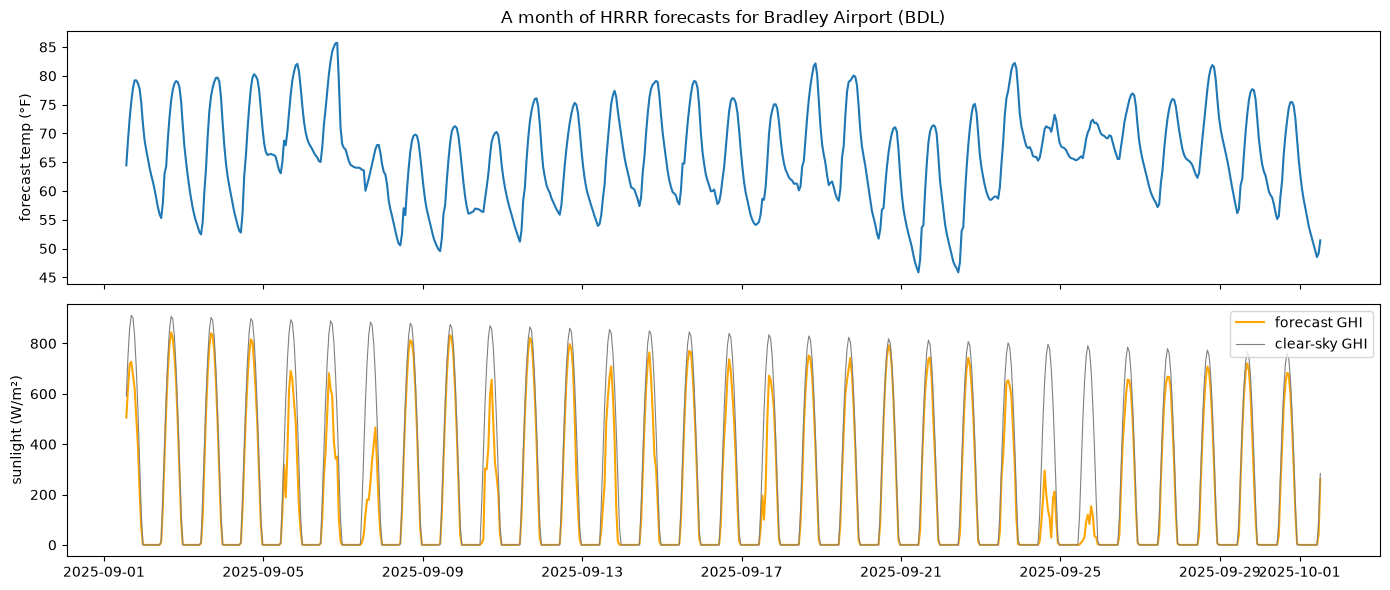

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(fcst.index, fcst['temp_air'] * 9 / 5 + 32)
axes[0].set_ylabel('forecast temp (°F)')
axes[1].plot(fcst.index, fcst['ghi'], color='orange', label='forecast GHI')
axes[1].plot(fcst.index, fcst['ghi_clear'], color='grey', linewidth=0.8, label='clear-sky GHI')
axes[1].set_ylabel('sunlight (W/m²)')
axes[1].legend()
axes[0].set_title('A month of HRRR forecasts for ' + SETTINGS['site'])
plt.tight_layout()
plt.show()

## Step 3: Connecticut load
The Lab 5 training file: one row per hour, ISO New England's Connecticut-zone load plus what was actually observed at Bradley.
`hour_utc` is the start of each hour, so we line the forecast up by rounding its mid-hour label down to the start of the hour.

In [9]:
load = pd.read_csv(SETTINGS['load_url'])
load['hour_utc'] = pd.to_datetime(load['hour_utc'], utc=True)
load = load.set_index('hour_utc')
print('full load file shape:', load.shape)
load[['load_mw', 'temp_f', 'cloud_cover_pct']].head()

full load file shape: (26304, 17)


,load_mw,temp_f,cloud_cover_pct
hour_utc,,,
2023-01-01 05:00:00+00:00,2402.708,50.0,100.0
2023-01-01 06:00:00+00:00,2296.444,50.0,100.0
2023-01-01 07:00:00+00:00,2206.413,50.0,100.0
2023-01-01 08:00:00+00:00,2165.396,48.0,75.0
2023-01-01 09:00:00+00:00,2153.655,48.0,44.0


In [10]:
# same hour yesterday: the simplest possible forecast, and the baseline to beat
load['load_yesterday_mw'] = load['load_mw'].shift(24)

fcst['hour_utc'] = fcst.index.floor('h')
data = fcst.reset_index().merge(load[['load_mw', 'load_yesterday_mw', 'temp_f', 'cloud_cover_pct']], left_on='hour_utc', right_index=True, how='inner')
data = data.set_index('hour_utc').sort_index()
data['temp_fcst_f'] = data['temp_air'] * 9 / 5 + 32
print('joined shape:', data.shape, '-> every forecast hour now has the load that actually happened')
data[['temp_fcst_f', 'temp_f', 'ghi', 'csi_ghi', 'load_mw', 'load_yesterday_mw']].head()

joined shape: (720, 19) -> every forecast hour now has the load that actually happened


,temp_fcst_f,temp_f,ghi,csi_ghi,load_mw,load_yesterday_mw
hour_utc,,,,,,
2025-09-01 13:00:00+00:00,64.449909,58.0,505.842038,0.858110,2415.889,2114.360
2025-09-01 14:00:00+00:00,68.796698,62.0,619.224366,0.828556,2487.316,2084.823
2025-09-01 15:00:00+00:00,72.551118,67.0,717.987588,0.837676,2648.612,2088.932
2025-09-01 16:00:00+00:00,75.513911,69.0,727.423065,0.800052,2713.815,2168.072
2025-09-01 17:00:00+00:00,77.842267,71.0,673.930444,0.749460,2764.272,2270.727


forecast temperature error: mean 0.6 °F | mean absolute 2.1 °F


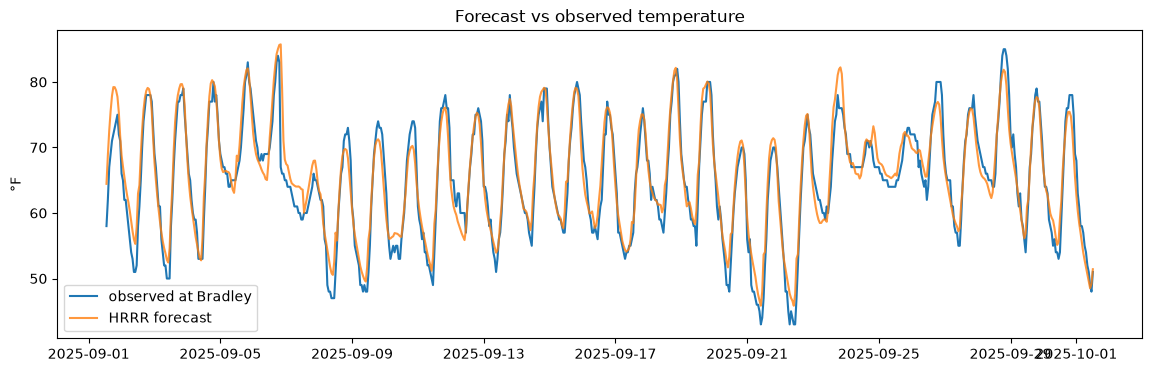

In [11]:
# how good was the forecast? compare forecast temperature with what Bradley actually measured
err = data['temp_fcst_f'] - data['temp_f']
print('forecast temperature error: mean', round(err.mean(), 1), '°F | mean absolute', round(err.abs().mean(), 1), '°F')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(data.index, data['temp_f'], label='observed at Bradley')
ax.plot(data.index, data['temp_fcst_f'], label='HRRR forecast', alpha=0.8)
ax.set_ylabel('°F')
ax.legend()
ax.set_title('Forecast vs observed temperature')
plt.show()

### Why sunlight matters for Connecticut load
ISO New England's load is what the grid supplies *after* rooftop solar. On a sunny afternoon the panels cover part of the
demand, so the measured load dips. Below: midday hours (11 a.m.-3 p.m. local), sunny vs cloudy.

midday rows: (150, 21)


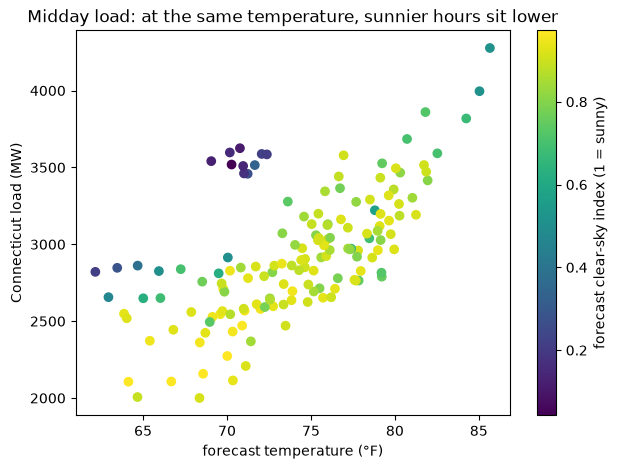

In [12]:
data['hour_local'] = data.index.tz_convert('America/New_York').hour
data['day_of_week'] = data.index.tz_convert('America/New_York').dayofweek
midday = data[(data['hour_local'] >= 11) & (data['hour_local'] <= 15)]
print('midday rows:', midday.shape)

fig, ax = plt.subplots(figsize=(7, 5))
points = ax.scatter(midday['temp_fcst_f'], midday['load_mw'], c=midday['csi_ghi'], cmap='viridis')
plt.colorbar(points, label='forecast clear-sky index (1 = sunny)')
ax.set_xlabel('forecast temperature (°F)')
ax.set_ylabel('Connecticut load (MW)')
ax.set_title('Midday load: at the same temperature, sunnier hours sit lower')
plt.show()

## Step 4: is the forecast worth it?
The same decision tree, trained three ways and scored on the same held-out last week. The only thing that changes is which
columns it is allowed to see:

| model | it sees | why it's here |
|---|---|---|
| **no weather** | hour of day, day of week, load at the same hour yesterday | what you could do with no weather data at all |
| **+ hefty forecast** | the above + the HRRR forecast (temperature, sunlight, clear-sky index, wind) | the honest version: only what was known at 8 a.m. |
| **+ actual weather** | the above + what Bradley really measured (temperature, cloud cover) | a cheat - nobody knows tomorrow's weather - so it shows the most a perfect forecast could add |

Plus the plain baseline, "same hour yesterday". If **+ hefty forecast** beats **no weather**, the forecast has value; how close it
gets to **+ actual weather** shows how much a better forecast could still add. Train on the first 23 days, test on the last 7, in
time order (no shuffling - the future can't leak into training).

In [13]:
TARGET = 'load_mw'
FEATURE_SETS = {
    'no weather': ['hour_local', 'day_of_week', 'load_yesterday_mw'],
    '+ hefty forecast': ['hour_local', 'day_of_week', 'load_yesterday_mw', 'temp_fcst_f', 'ghi', 'csi_ghi', 'wind_speed'],
    '+ actual weather (cheat)': ['hour_local', 'day_of_week', 'load_yesterday_mw', 'temp_f', 'cloud_cover_pct'],
}

data = data.dropna(subset=['load_yesterday_mw'])
cut = data.index.max() - pd.Timedelta(days=SETTINGS['test_days'])
train = data[data.index <= cut]
test = data[data.index > cut]
y_train = train[TARGET]
y_test = test[TARGET]
print('train:', train.shape, '| test:', test.shape)
print('training hours:', train.index.min(), '->', train.index.max())
print('testing hours: ', test.index.min(), '->', test.index.max())

train: (552, 21) | test: (168, 21)
training hours: 2025-09-01 13:00:00+00:00 -> 2025-09-24 12:00:00+00:00
testing hours:  2025-09-24 13:00:00+00:00 -> 2025-10-01 12:00:00+00:00


In [14]:
results = {}
predictions = {}
trees = {}
results['same hour yesterday'] = mean_absolute_error(y_test, test['load_yesterday_mw'])
predictions['same hour yesterday'] = test['load_yesterday_mw'].values

for name in FEATURE_SETS:
    cols = FEATURE_SETS[name]
    X_train = train[cols]
    X_test = test[cols]
    print(name.ljust(26), 'X_train', X_train.shape, ' X_test', X_test.shape)
    tree = DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=SETTINGS['seed'])
    tree.fit(X_train, y_train)
    predictions[name] = tree.predict(X_test)
    results[name] = mean_absolute_error(y_test, predictions[name])
    trees[name] = tree

scoreboard = pd.DataFrame({'test MAE (MW)': pd.Series(results)})
scoreboard['% of average load'] = 100 * scoreboard['test MAE (MW)'] / y_test.mean()
scoreboard = scoreboard.sort_values('test MAE (MW)').round(1)
print()
print('average load in the test week:', round(y_test.mean()), 'MW')
scoreboard

no weather                 X_train (552, 3)  X_test (168, 3)
+ hefty forecast           X_train (552, 7)  X_test (168, 7)
+ actual weather (cheat)   X_train (552, 5)  X_test (168, 5)

average load in the test week: 2968 MW


,test MAE (MW),% of average load
no weather,159.0,5.4
same hour yesterday,175.7,5.9
+ actual weather (cheat),190.7,6.4
+ hefty forecast,190.8,6.4


In [15]:
gain = results['no weather'] - results['+ hefty forecast']
room = results['+ hefty forecast'] - results['+ actual weather (cheat)']
print('adding the hefty forecast changed the error by', round(-gain, 1), 'MW', '(negative = better)')
print('a perfect forecast could have cut another', round(room, 1), 'MW')

adding the hefty forecast changed the error by 31.8 MW (negative = better)
a perfect forecast could have cut another 0.2 MW


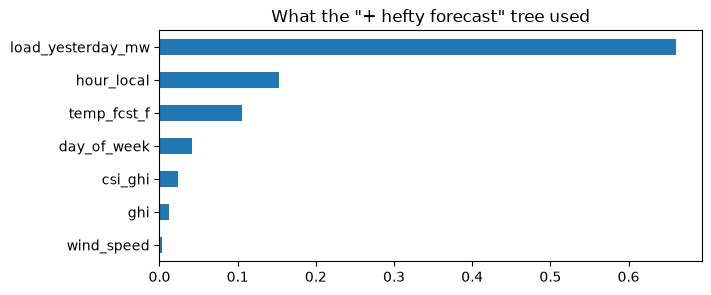

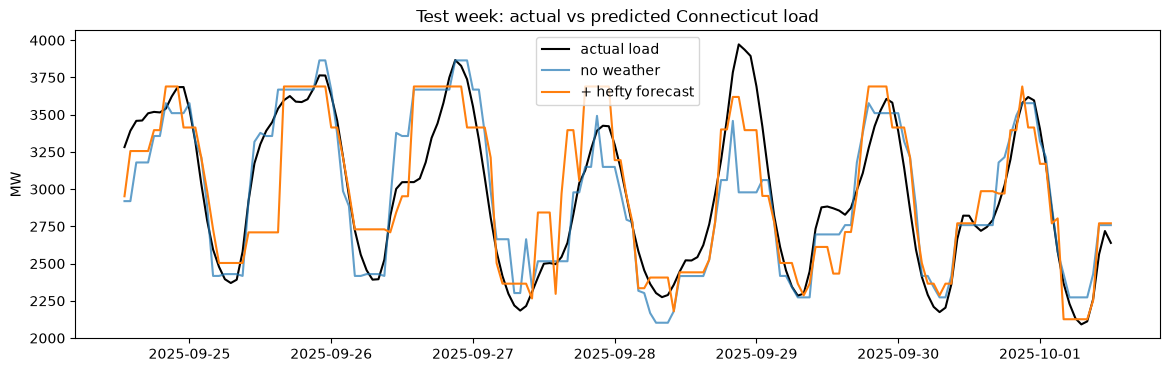

In [16]:
importance = pd.Series(trees['+ hefty forecast'].feature_importances_, index=FEATURE_SETS['+ hefty forecast']).sort_values()
importance.plot(kind='barh', figsize=(7, 3), title='What the "+ hefty forecast" tree used')
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(test.index, y_test, label='actual load', color='black')
ax.plot(test.index, predictions['no weather'], label='no weather', alpha=0.7)
ax.plot(test.index, predictions['+ hefty forecast'], label='+ hefty forecast')
ax.set_ylabel('MW')
ax.legend()
ax.set_title('Test week: actual vs predicted Connecticut load')
plt.show()

## Step 5: a fairer test - learn from years of history, then feed it the forecast
A month is too little for a tree to learn how weather moves load (Step 4 shows it: even the perfect-weather cheat doesn't help).
So do it the way a real model would be used:
1. **Train** on the 2.5 years before September 2025, where we have the temperature Bradley actually measured.
2. **Test** on September 2025, feeding the same trained tree either the temperature that really happened (the cheat) or Will's
   forecast temperature from 8 a.m. that morning (what you would really have).

Temperature only, because it is the one weather column the history file and the forecast both have.

In [17]:
hist = load.copy()
hist['hour_local'] = hist.index.tz_convert('America/New_York').hour
hist['day_of_week'] = hist.index.tz_convert('America/New_York').dayofweek
hist['month'] = hist.index.tz_convert('America/New_York').month
history = hist[hist.index < data.index.min()].dropna(subset=['load_yesterday_mw'])
september = hist.loc[data.index].copy()
september['temp_fcst_f'] = data['temp_fcst_f']
print('history (training):', history.shape, history.index.min(), '->', history.index.max())
print('September (testing):', september.shape)

CLOCK = ['hour_local', 'day_of_week', 'month', 'load_yesterday_mw']
WITH_TEMP = ['hour_local', 'day_of_week', 'month', 'load_yesterday_mw', 'temp_f']

tree_clock = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SETTINGS['seed'])
tree_clock.fit(history[CLOCK], history['load_mw'])
tree_temp = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SETTINGS['seed'])
tree_temp.fit(history[WITH_TEMP], history['load_mw'])

X_actual = september[WITH_TEMP]
X_forecast = september[WITH_TEMP].copy()
X_forecast['temp_f'] = september['temp_fcst_f']      # swap in Will's forecast for the real temperature

fair = {}
fair['same hour yesterday'] = mean_absolute_error(september['load_mw'], september['load_yesterday_mw'])
fair['no weather'] = mean_absolute_error(september['load_mw'], tree_clock.predict(september[CLOCK]))
fair['+ hefty forecast temperature'] = mean_absolute_error(september['load_mw'], tree_temp.predict(X_forecast))
fair['+ actual temperature (cheat)'] = mean_absolute_error(september['load_mw'], tree_temp.predict(X_actual))
fair_board = pd.DataFrame({'September MAE (MW)': pd.Series(fair)})
fair_board['% of average load'] = 100 * fair_board['September MAE (MW)'] / september['load_mw'].mean()
fair_board.sort_values('September MAE (MW)').round(1)

history (training): (23360, 20) 2023-01-02 05:00:00+00:00 -> 2025-09-01 12:00:00+00:00
September (testing): (720, 21)


,September MAE (MW),% of average load
+ actual temperature (cheat),155.5,5.5
+ hefty forecast temperature,158.0,5.6
no weather,169.2,6.0
same hour yesterday,197.8,7.0


In [18]:
possible = fair['no weather'] - fair['+ actual temperature (cheat)']
captured = fair['no weather'] - fair['+ hefty forecast temperature']
print('perfect knowledge of the temperature would cut the error by', round(possible, 1), 'MW')
print('the hefty forecast cut it by', round(captured, 1), 'MW')
print('-> the forecast delivers', round(100 * captured / possible), '% of the possible gain')

perfect knowledge of the temperature would cut the error by 13.7 MW
the hefty forecast cut it by 11.2 MW
-> the forecast delivers 82 % of the possible gain


## What to take from this
- **Shape of the data:** one forecast run per morning × 24 hours = 720 rows for a month; each row carries `lead_time`, so we
  always know how far ahead the forecast was.
- **The forecasts are honest:** these are the numbers that were available at 8 a.m. that day, not the weather that happened -
  exactly what a live model would see.
- **Sunlight belongs in a Connecticut load model:** rooftop solar pulls midday load down on sunny days.
- **Step 4 vs Step 5:** with only a month to learn from, weather didn't help at all - not even perfect weather. Trained on
  years of history, the forecast earns its keep (Step 5). The forecast is fine; a month of training data is the problem.
- **Read the scoreboards with care:** a test week is 168 hours and September 720, so a few MW either way is noise. September is also mild -
  weather matters most for load in summer heat and winter cold, so this month is a hard test for the forecast, not an easy one.
- **One month is a toy:** a real answer needs a year or more (seasons), which is the backfill we'd run once for everyone.

Next steps worth trying: switch `'model'` to `'gfs'` and compare, add more months, change `first_init` to a hot month like
`'2025-07-01 12:00'`, add `lead_time` as a feature, or try a random forest or an LSTM on the same table.